<a href="https://colab.research.google.com/github/sonhh-3626/data-science-economics/blob/main/NEU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Đọc và tải dữ liệu `tips`

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

display(df.head())
print(df.info())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB
None


### 1. Khai phá dữ liệu cơ bản và nhận xét
Chúng ta sẽ xem xét các thông số thống kê mô tả của các cột số và các giá trị duy nhất của các cột phân loại.

In [3]:
# Thống kê mô tả dữ liệu số
display(df.describe())

# Thống kê dữ liệu phân loại
for col in ['sex', 'smoker', 'day', 'time']:
    print(f"Tần suất cho cột '{col}':")
    print(df[col].value_counts())
    print("-" * 30)

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


Tần suất cho cột 'sex':
sex
Male      157
Female     87
Name: count, dtype: int64
------------------------------
Tần suất cho cột 'smoker':
smoker
No     151
Yes     93
Name: count, dtype: int64
------------------------------
Tần suất cho cột 'day':
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
------------------------------
Tần suất cho cột 'time':
time
Dinner    176
Lunch      68
Name: count, dtype: int64
------------------------------


### 2. Sự chênh lệch về giá trị hóa đơn (`total_bill`) theo thời gian ăn (`time`) và số lượng người (`size`)

Hóa đơn theo thời gian ăn:


,mean,median,count
time,,,
Dinner,20.797159,18.390,176
Lunch,17.168676,15.965,68



Hóa đơn theo số lượng người trong nhóm:


,mean,median,count
size,,,
1,7.242500,7.915,4
2,16.448013,15.370,156
3,23.277632,20.365,38
4,28.613514,25.890,37
5,30.068000,29.850,5
6,34.830000,32.050,4


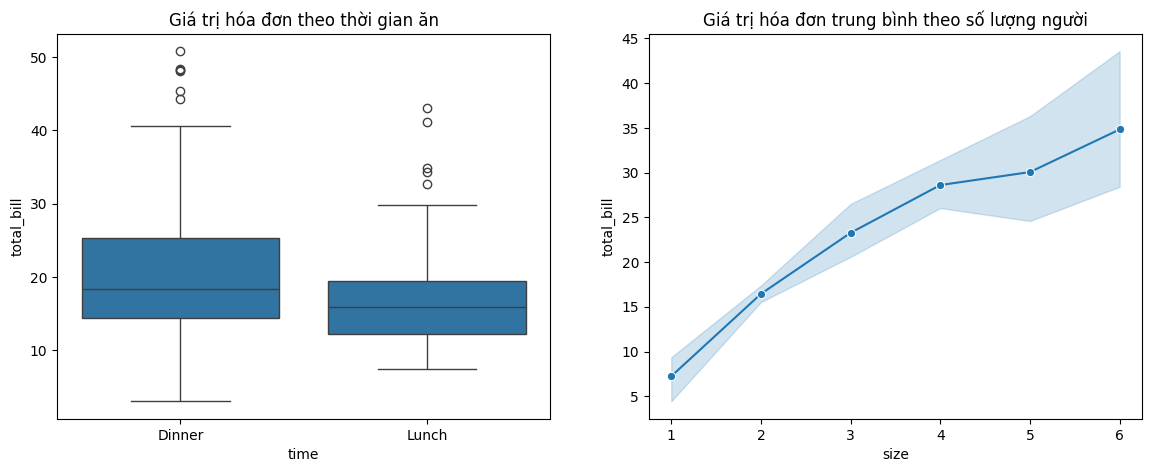

In [4]:
# Phân tích hóa đơn theo thời gian ăn
group_time = df.groupby('time')['total_bill'].agg(['mean', 'median', 'count'])
print("Hóa đơn theo thời gian ăn:")
display(group_time)

# Phân tích hóa đơn theo số lượng người
group_size = df.groupby('size')['total_bill'].agg(['mean', 'median', 'count'])
print("\nHóa đơn theo số lượng người trong nhóm:")
display(group_size)

# Trực quan hóa mối quan hệ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='time', y='total_bill', ax=axes[0])
axes[0].set_title('Giá trị hóa đơn theo thời gian ăn')

sns.lineplot(data=df, x='size', y='total_bill', marker='o', ax=axes[1])
axes[1].set_title('Giá trị hóa đơn trung bình theo số lượng người')
plt.show()

### 3. So sánh nhóm khách hàng có hút thuốc (`smoker = Yes`) và không hút thuốc (`smoker = No`)

total_bill                    tip             
             mean median count      mean median count
smoker                                               
No      19.188278  17.59   151  2.991854   2.74   151
Yes     20.756344  17.92    93  3.008710   3.00    93

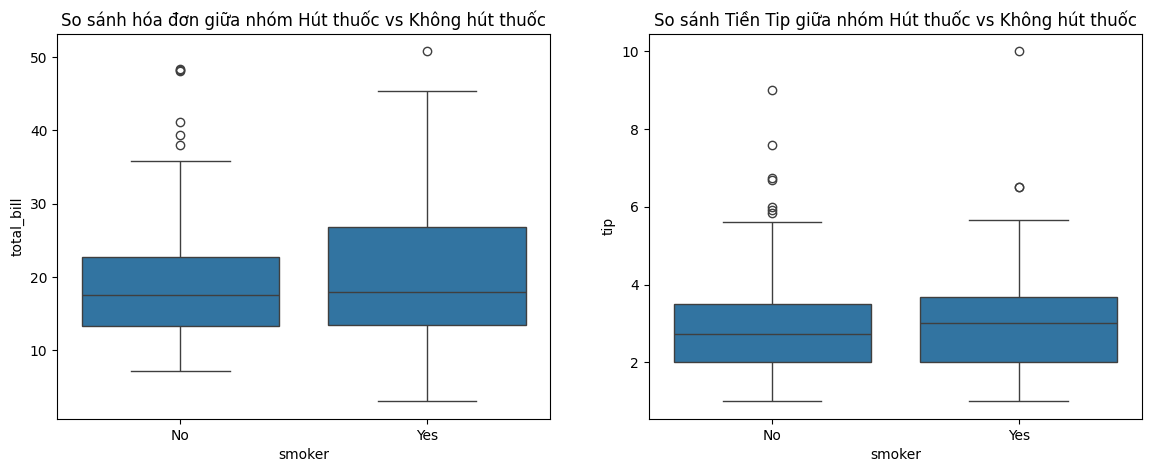

In [5]:
# Tính toán hóa đơn và tiền tip trung bình của 2 nhóm
smoker_analysis = df.groupby('smoker')[['total_bill', 'tip']].agg(['mean', 'median', 'count'])
display(smoker_analysis)

# Trực quan hóa so sánh
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='smoker', y='total_bill', ax=axes[0])
axes[0].set_title('So sánh hóa đơn giữa nhóm Hút thuốc vs Không hút thuốc')

sns.boxplot(data=df, x='smoker', y='tip', ax=axes[1])
axes[1].set_title('So sánh Tiền Tip giữa nhóm Hút thuốc vs Không hút thuốc')
plt.show()

### 4. Đánh giá khách hàng Nam hay Nữ chi nhiều hơn vào cuối tuần (Thứ 7 & Chủ Nhật) và thường đi ăn vào buổi nào?

Thống kê chi tiêu của Nam và Nữ vào cuối tuần:


,sum,mean,count
sex,,,
Female,908.75,19.755435,46
Male,2496.81,21.340256,117



Số lượt đi ăn theo buổi của Nam và Nữ vào cuối tuần:


time,Dinner
sex,
Female,46
Male,117


/tmp/ipykernel_4383/3120711725.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=weekend_df, x='sex', y='total_bill', hue='time', ci=None)


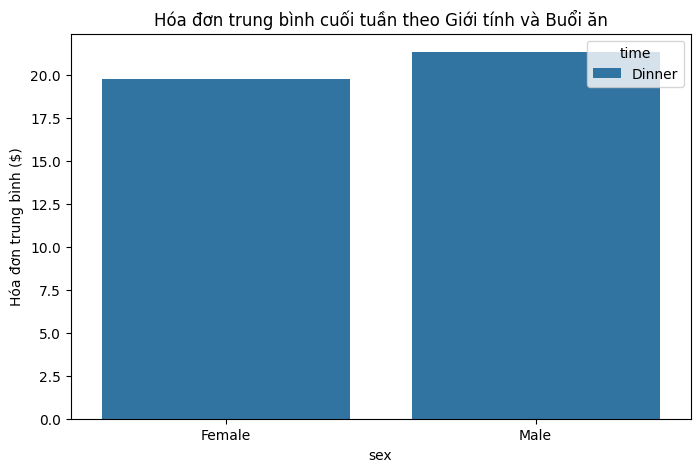

In [6]:
# Lọc dữ liệu cuối tuần (Saturday, Sunday)
weekend_df = df[df['day'].isin(['Sat', 'Sun'])]

# So sánh chi tiêu (total_bill) giữa Nam và Nữ vào cuối tuần
weekend_gender = weekend_df.groupby('sex')['total_bill'].agg(['sum', 'mean', 'count'])
print("Thống kê chi tiêu của Nam và Nữ vào cuối tuần:")
display(weekend_gender)

# Phân tích xem họ thường đi ăn vào buổi trưa hay tối vào cuối tuần
weekend_time = weekend_df.groupby(['sex', 'time']).size().unstack(fill_value=0)
print("\nSố lượt đi ăn theo buổi của Nam và Nữ vào cuối tuần:")
display(weekend_time)

# Trực quan hóa
plt.figure(figsize=(8, 5))
sns.barplot(data=weekend_df, x='sex', y='total_bill', hue='time', ci=None)
plt.title('Hóa đơn trung bình cuối tuần theo Giới tính và Buổi ăn')
plt.ylabel('Hóa đơn trung bình ($)')
plt.show()